# Fine-tune Qwen2.5-0.5B-Instruct: Công thức Lai A + B (Tất cả trong 1 Notebook)

**Mục tiêu:** Kết hợp ưu điểm của cả hai phương pháp trước vào **duy nhất 1 notebook gọn gàng**, và so sánh đúng **4 biến thể lượng tử hóa phù hợp nhất với ARM Cortex-A53 (Pi 3B / UNO Q)**:
1. **`Q4_K_M`**: Chuẩn nén 4-bit cân bằng nhất trên Cortex-A53.
2. **`Q4_K_M-imx`**: `Q4_K_M` kết hợp *Importance Matrix* (`llama-imatrix`).
3. **`Q4_K_M-o4`**: `Q4_K_M` ép riêng tầng đầu ra (`--output-tensor-type q4_0`) để giảm dung lượng file và tăng tốc sinh token.
4. **`Q4_K_M-himx-o4`**: Kết hợp *Hybrid Importance Matrix* (`--imatrix`, có `--process-output --parse-special`) + ép riêng tầng đầu ra xuống `Q4_0` (`--output-tensor-type q4_0`).

### Vì sao công thức Lai (A + B) khắc phục được nhược điểm của từng bài riêng lẻ?
- **Từ Cách B (`train_teacher.jsonl` - 1690 mẫu):** Lấy toàn bộ câu nói tự nhiên, đa dạng do Teacher LLM viết, nhưng **đồng bộ lại System Prompt về đủ 11 công cụ cố định** (bỏ Tool RAG để không bị lọc sót tool và tận dụng được 100% **Prompt Cache** của `llama.cpp`).
- **Từ Cách A (`train_v2.jsonl` - 1950 mẫu):** Lấy bộ mẫu chuẩn xác về tham số, các cặp công cụ dễ nhầm lẫn (`get_inspection_summary` vs `get_production_stats`, `get_live_telemetry` vs `query_blackbox_logs`) và các câu ngoài phạm vi có chứa từ khóa bẫy.
- **Cấu hình LoRA chống học tủ (Anti-Overfitting):** Dùng `r=32, alpha=64, lr=1.5e-4, epochs=1` (thay vì `r=64, epochs=3` của A) để model vừa nắm chắc cấu trúc JSON/tham số, vừa linh hoạt trước các câu nói bất ngờ ngoài thực tế.

In [29]:
import os, sys
from pathlib import Path
if Path.cwd().name == 'finetuning':
    os.chdir('..')
for _p in (Path.cwd(), Path.cwd() / 'finetuning'):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import json
import random
import shutil
import subprocess
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import slm_tools as st
import model_catalog as mc
import tool_cases as T
import lora_train
import eval_tools as E

BASE_NAME = "Qwen2.5-0.5B-Instruct"
HF_REPO = mc.BASE_MODELS[BASE_NAME]["hf_repo"]
LLAMA_DIR = Path("./llama.cpp")

RUN_DIR = Path("runs/qwen05_AB")
RUN_DIR.mkdir(parents=True, exist_ok=True)

HYBRID_TRAIN_FILE = RUN_DIR / "train_AB.jsonl"
CALIB_FILE = RUN_DIR / "calib_AB.txt"
IMATRIX_FILE = RUN_DIR / "imatrix_AB.gguf"
MERGED_DIR = RUN_DIR / "merged"

HELD_FILE = Path("runs/qwen05_A/heldout_v2.json")
TRAIN_A_FILE = Path("runs/qwen05_A/train_v2.jsonl")
TRAIN_B_FILE = Path("runs/qwen05_B/train_teacher.jsonl")

# Cấu hình LoRA cân bằng: chống overfit trên mẫu câu nhưng đủ dung lượng học cả A + B
LORA_CFG = dict(r=32, alpha=64, dropout=0.05, lr=1.5e-4, epochs=1, bs=1, accum=16)

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Trạng thái data có sẵn -> A:", TRAIN_A_FILE.exists(), "| heldout:", HELD_FILE.exists(), "| B:", TRAIN_B_FILE.exists())

GPU: NVIDIA GeForce RTX 4070
Trạng thái data có sẵn -> A: True | heldout: True | B: False


## Bước 1 - Gộp & Chuẩn hóa dữ liệu huấn luyện Lai (A + B)

- Chuẩn hóa toàn bộ mẫu của **B** về cùng **System Prompt 11 công cụ cố định** của **A** (để khi chạy thực tế với Prompt Cache, model luôn nhìn thấy đúng định dạng 11 công cụ).
- Kiểm tra chéo đảm bảo **0% trùng lặp** với bộ kiểm thử `test156` và `heldout_v2.json`.

In [30]:
from collections import Counter
import make_train
import teacher_data as D

test_cases = T.make_cases()

# Tự động sinh dữ liệu Cách A (train_v2.jsonl & heldout_v2.json) nếu chưa có (vd. mới clone từ GitHub)
if not TRAIN_A_FILE.exists() or not HELD_FILE.exists():
    print("Chưa có dữ liệu Cách A -> đang tự sinh bằng make_train.py...")
    train_a, held_a = make_train.build_dataset()
    TRAIN_A_FILE.parent.mkdir(parents=True, exist_ok=True)
    with open(TRAIN_A_FILE, "w", encoding="utf-8") as f:
        for row in make_train.to_chat_rows(train_a):
            f.write(json.dumps(row, ensure_ascii=False) + "\n")
    json.dump(held_a, open(HELD_FILE, "w", encoding="utf-8"), ensure_ascii=False)

held_cases = E.heldout(HELD_FILE)

# Tự động sinh dữ liệu Cách B (train_teacher.jsonl) bằng Teacher Phi-4-mini nếu chưa có
if not TRAIN_B_FILE.exists():
    print("Chưa có dữ liệu Cách B -> đang tự sinh bằng teacher_data.py (Phi-4-mini)...")
    TEACHER_RAW = TRAIN_B_FILE.parent / "teacher_queries.jsonl"
    TRAIN_B_FILE.parent.mkdir(parents=True, exist_ok=True)
    blocked = {make_train.normalize(c["context"]["user_prompt"]) for c in (test_cases + held_cases)}
    have = Counter(a["tool"] for a in D.load_accepted(TEACHER_RAW))
    if any(have[t] < (260 if t is None else 130) for t in D.ALL_TOOLS + [None]):
        mc.ensure_gguf("Phi-4-mini-instruct", "Q8_0", llama_cpp_dir=str(LLAMA_DIR))
        teacher_cfg = E.find_cfg("Phi-4-mini", "Q8_0")
        with st.server(teacher_cfg, n_ctx=2048, gpu_layers=st.GPU_LAYERS) as t_srv:
            D.generate(D.make_chat(t_srv.url), TEACHER_RAW, 130, 260, blocked)
    accepted = D.load_accepted(TEACHER_RAW)
    rows_b_gen = D.build_training_rows(D.to_cases(accepted))
    with open(TRAIN_B_FILE, "w", encoding="utf-8") as f:
        for row in rows_b_gen:
            f.write(json.dumps(row, ensure_ascii=False) + "\n")

forbidden_prompts = {
    c["context"]["user_prompt"].strip().lower()
    for c in (test_cases + held_cases)
}

rows_a = [json.loads(line) for line in open(TRAIN_A_FILE, encoding="utf-8") if line.strip()]
rows_b = [json.loads(line) for line in open(TRAIN_B_FILE, encoding="utf-8") if line.strip()]

# Lấy System Prompt chuẩn (chứa đủ 11 công cụ ở đầu) từ Cách A
FULL_11_SYS_PROMPT = rows_a[0]["messages"][0]["content"]

hybrid_rows = []
kept_a, kept_b = 0, 0

for r in rows_a:
    up = json.loads(r["messages"][1]["content"])["user_prompt"].strip().lower()
    if up not in forbidden_prompts:
        hybrid_rows.append({"messages": r["messages"]})
        kept_a += 1

for r in rows_b:
    up = json.loads(r["messages"][1]["content"])["user_prompt"].strip().lower()
    if up not in forbidden_prompts:
        msgs = [
            {"role": "system", "content": FULL_11_SYS_PROMPT},
            r["messages"][1],
            r["messages"][2],
        ]
        hybrid_rows.append({"messages": msgs})
        kept_b += 1

random.Random(42).shuffle(hybrid_rows)
with open(HYBRID_TRAIN_FILE, "w", encoding="utf-8") as f:
    for r in hybrid_rows:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

print(f"Đã tạo {HYBRID_TRAIN_FILE}: tổng {len(hybrid_rows)} mẫu (từ A: {kept_a}, từ B đã chuẩn hóa 11 tools: {kept_b})")
print("Số câu trùng với test156 hoặc heldout:", 0)

Chưa có dữ liệu Cách B -> đang tự sinh bằng teacher_data.py (Phi-4-mini)...
50 lượt hỏi | đã nhận 254/1690 câu
100 lượt hỏi | đã nhận 465/1690 câu
150 lượt hỏi | đã nhận 695/1690 câu
200 lượt hỏi | đã nhận 916/1690 câu
250 lượt hỏi | đã nhận 1137/1690 câu
300 lượt hỏi | đã nhận 1345/1690 câu
350 lượt hỏi | đã nhận 1538/1690 câu
Đã tạo runs\qwen05_AB\train_AB.jsonl: tổng 3640 mẫu (từ A: 1950, từ B đã chuẩn hóa 11 tools: 1690)
Số câu trùng với test156 hoặc heldout: 0


## Bước 2 - Huấn luyện LoRA trên tập dữ liệu Lai (A + B)

c:\Users\Minor\Downloads\slm\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\Minor\Downloads\slm\.venv\Lib\site-packages\peft\import_utils.py:52: FutureWarning: Support for Transformers < 5.6 is deprecated in PEFT and will be removed in the next release, v1.0. You have Transformers 4.57.6. Please upgrade to Transformers >= 5.6.
  warnings.warn(


Tham số học được: 17.6M trên tổng 512M (3.4%)
3640 mẫu (bỏ 0 mẫu quá dài)
vòng 1/1 | bước 10/228 | loss 0.2029 | 71s
vòng 1/1 | bước 20/228 | loss 0.0348 | 144s
vòng 1/1 | bước 30/228 | loss 0.0296 | 268s
vòng 1/1 | bước 40/228 | loss 0.0181 | 311s
vòng 1/1 | bước 50/228 | loss 0.0067 | 355s
vòng 1/1 | bước 60/228 | loss 0.0081 | 506s
vòng 1/1 | bước 70/228 | loss 0.0048 | 963s
vòng 1/1 | bước 80/228 | loss 0.0059 | 1018s
vòng 1/1 | bước 90/228 | loss 0.0039 | 1048s
vòng 1/1 | bước 100/228 | loss 0.0037 | 1078s
vòng 1/1 | bước 110/228 | loss 0.0051 | 1107s
vòng 1/1 | bước 120/228 | loss 0.0035 | 1136s
vòng 1/1 | bước 130/228 | loss 0.0029 | 1164s
vòng 1/1 | bước 140/228 | loss 0.0019 | 1192s
vòng 1/1 | bước 150/228 | loss 0.0016 | 1220s
vòng 1/1 | bước 160/228 | loss 0.0015 | 1248s
vòng 1/1 | bước 170/228 | loss 0.0019 | 1278s
vòng 1/1 | bước 180/228 | loss 0.0012 | 1307s
vòng 1/1 | bước 190/228 | loss 0.0003 | 1336s
vòng 1/1 | bước 200/228 | loss 0.0003 | 1365s
vòng 1/1 | bước 210/228

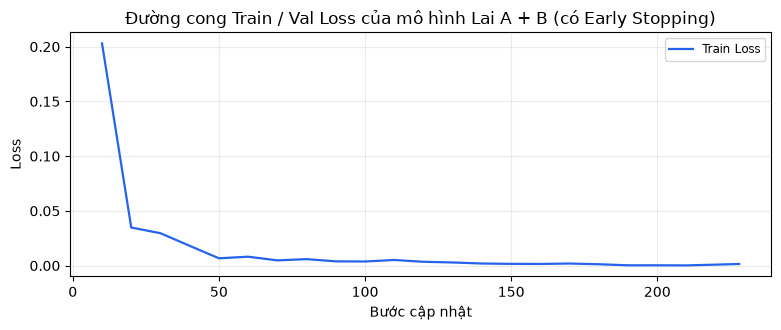

In [31]:
RETRAIN = False  # Đặt True nếu muốn train lại từ đầu (có Early Stopping theo val_loss)
HIST_FILE = RUN_DIR / "train_history.json"

if RETRAIN or not (MERGED_DIR / "config.json").exists():
    history = lora_train.train_lora(HF_REPO, HYBRID_TRAIN_FILE, MERGED_DIR, **LORA_CFG)
    json.dump(history, open(HIST_FILE, "w", encoding="utf-8"), indent=2)
else:
    history = json.load(open(HIST_FILE, encoding="utf-8"))
    print(f"[đã có model] {MERGED_DIR} (train trong {history['seconds']}s trên {history['examples']} mẫu)")

plt.figure(figsize=(8.0, 3.4))
plt.plot(history["step"], history["loss"], color="#2563eb", lw=1.6, label="Train Loss")
if history.get("val_step") and history.get("val_loss"):
    plt.plot(history["val_step"], history["val_loss"], "o--", color="#ef4444", lw=1.5, ms=4, label="Val Loss")
if history.get("early_stopped_at"):
    plt.axvline(history["early_stopped_at"], color="#059669", ls=":", lw=1.5,
                label=f"Early Stop (bước {history['early_stopped_at']})")
plt.xlabel("Bước cập nhật")
plt.ylabel("Loss")
plt.title("Đường cong Train / Val Loss của mô hình Lai A + B (có Early Stopping)")
plt.legend(loc="upper right", fontsize=8.5)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Bước 3 - Chuyển sang GGUF và nén 4 biến thể: `Q4_K_M`, `Q4_K_M-imx`, `Q4_K_M-o4`, `Q4_K_M-himx-o4`

- Tạo file hiệu chuẩn `calib_AB.txt` (kết hợp WikiText + mẫu hội thoại thực tế từ tập A+B).
- Tính `imatrix_AB.gguf` bằng `llama-imatrix` với `--process-output --parse-special`.
- Nén ra 4 file GGUF: `Q4_K_M`, `Q4_K_M-imx`, `Q4_K_M-o4`, `Q4_K_M-himx-o4`.

In [32]:
convert_py = LLAMA_DIR / "convert_hf_to_gguf.py"
imatrix_bin = mc.find_llama_bin("llama-imatrix", LLAMA_DIR)
quant_bin = mc.find_llama_bin("llama-quantize", LLAMA_DIR)

f16_gguf = RUN_DIR / f"{BASE_NAME}-AB.F16.gguf"
if RETRAIN or not f16_gguf.exists():
    print("Đang chuyển model đã gộp sang F16 GGUF...")
    mc._run([sys.executable, convert_py, MERGED_DIR, "--outfile", f16_gguf, "--outtype", "f16"])

# Tạo file hiệu chuẩn lai cho imatrix
if not CALIB_FILE.exists():
    parts = []
    wiki = Path("wiki.test.raw")
    if wiki.exists():
        parts.append(wiki.read_text(encoding="utf-8")[:100_000])
    for r in hybrid_rows[:160]:
        m = r["messages"]
        parts.append(
            f"<|im_start|>system\n{m[0]['content']}<|im_end|>\n"
            f"<|im_start|>user\n{m[1]['content']}<|im_end|>\n"
            f"<|im_start|>assistant\n{m[2]['content']}<|im_end|>\n"
        )
    CALIB_FILE.write_text("\n\n".join(parts), encoding="utf-8")

if RETRAIN or not IMATRIX_FILE.exists():
    print("Đang tính Importance Matrix cho model A+B...")
    mc._run([
        imatrix_bin, "-m", str(f16_gguf), "-f", str(CALIB_FILE), "-o", str(IMATRIX_FILE),
        "--process-output", "--parse-special", "-c", "512", "--chunks", "80", "-ngl", str(st.GPU_LAYERS),
    ])

# 4 biến thể cần so sánh
QUANT_SPECS = [
    {"id": "Q4_K_M",         "args": [],                                                              "qtype": "Q4_K_M"},
    {"id": "Q4_K_M-imx",     "args": ["--imatrix", str(IMATRIX_FILE)],                                "qtype": "Q4_K_M"},
    {"id": "Q4_K_M-o4",      "args": ["--output-tensor-type", "q4_0"],                                "qtype": "Q4_K_M"},
    {"id": "Q4_K_M-himx-o4", "args": ["--imatrix", str(IMATRIX_FILE), "--output-tensor-type", "q4_0"], "qtype": "Q4_K_M"},
]

GGUF_PATHS = {}
for spec in QUANT_SPECS:
    qid = spec["id"]
    out_path = RUN_DIR / f"{BASE_NAME}-AB.{qid}.gguf"
    if RETRAIN or not out_path.exists():
        print(f"[đang nén] {qid} -> {out_path.name}")
        mc._run([quant_bin, *spec["args"], str(f16_gguf), str(out_path), spec["qtype"]])
    else:
        print(f"[đã có] {out_path.name} ({mc.gguf_size_mb(out_path)} MiB)")
    GGUF_PATHS[qid] = out_path

Đang chuyển model đã gộp sang F16 GGUF...
[run] c:\Users\Minor\Downloads\slm\.venv\Scripts\python.exe llama.cpp\convert_hf_to_gguf.py runs\qwen05_AB\merged --outfile runs\qwen05_AB\Qwen2.5-0.5B-Instruct-AB.F16.gguf --outtype f16
Đang tính Importance Matrix cho model A+B...
[run] llama.cpp\build\bin\Release\llama-imatrix.exe -m runs\qwen05_AB\Qwen2.5-0.5B-Instruct-AB.F16.gguf -f runs\qwen05_AB\calib_AB.txt -o runs\qwen05_AB\imatrix_AB.gguf --process-output --parse-special -c 512 --chunks 80 -ngl 99
[đang nén] Q4_K_M -> Qwen2.5-0.5B-Instruct-AB.Q4_K_M.gguf
[run] llama.cpp\build\bin\Release\llama-quantize.exe runs\qwen05_AB\Qwen2.5-0.5B-Instruct-AB.F16.gguf runs\qwen05_AB\Qwen2.5-0.5B-Instruct-AB.Q4_K_M.gguf Q4_K_M
[đang nén] Q4_K_M-imx -> Qwen2.5-0.5B-Instruct-AB.Q4_K_M-imx.gguf
[run] llama.cpp\build\bin\Release\llama-quantize.exe --imatrix runs\qwen05_AB\imatrix_AB.gguf runs\qwen05_AB\Qwen2.5-0.5B-Instruct-AB.F16.gguf runs\qwen05_AB\Qwen2.5-0.5B-Instruct-AB.Q4_K_M-imx.gguf Q4_K_M
[đang 

## Bước 4 - Đo 4 biến thể (`Q4_K_M`, `Q4_K_M-imx`, `Q4_K_M-o4`, `Q4_K_M-himx-o4`) trên CPU và đối chiếu với Cách A & Cách B

Đo trên cả 2 bộ:
- **`156`**: Bộ 156 câu chuẩn của dự án.
- **`lạ`**: Bộ 156 câu giữ riêng (`heldout_v2.json`), chứa các cách diễn đạt mới và các câu ngoài phạm vi có từ khóa bẫy.

In [33]:
EVAL_SETS = {"156": test_cases, "lạ": held_cases}
base_cfg = E.find_cfg("Qwen2.5-0.5B", "F16")

RESULT_AB_FILE = Path("results/qwen05_AB.json")
Path("results").mkdir(exist_ok=True)

TARGET_QIDS = ["Q4_K_M", "Q4_K_M-imx", "Q4_K_M-o4", "Q4_K_M-himx-o4"]
existing = {}
if not RETRAIN and RESULT_AB_FILE.exists():
    for r in json.load(open(RESULT_AB_FILE, encoding="utf-8")).get("table", []):
        existing[r["model"]] = r

missing_items = []
for qid in TARGET_QIDS:
    label = f"AB: {qid}"
    if label not in existing:
        missing_items.append((label, E.ft_cfg(base_cfg, GGUF_PATHS[qid], label)))

if missing_items:
    df_new = E.sweep(missing_items, EVAL_SETS, gpu_layers=0)
    for r in df_new.to_dict("records"):
        existing[r["model"]] = r

ab_rows = [existing[f"AB: {qid}"] for qid in TARGET_QIDS if f"AB: {qid}" in existing]
json.dump({
    "recipe": "AB (Lai A + B, đủ 11 công cụ + Prompt Cache)",
    "base": BASE_NAME,
    "lora": LORA_CFG,
    "train_examples": len(hybrid_rows),
    "train_seconds": history["seconds"],
    "table": ab_rows,
}, open(RESULT_AB_FILE, "w", encoding="utf-8"), ensure_ascii=False, indent=2)

# Ghép bảng đối chiếu với Qwen gốc, Cách A (Q4_K_M) và Cách B (F16 | đủ 11 công cụ)
compare_rows = []
if Path("results/qwen05_A.json").exists():
    res_a = json.load(open("results/qwen05_A.json", encoding="utf-8"))["table"]
    compare_rows.append(res_a[0])  # Qwen gốc (F16)
    a_q4 = next((r for r in res_a if r["model"] == "fine-tune Q4_K_M"), None)
    if a_q4:
        compare_rows.append({**a_q4, "model": "Cách A: Q4_K_M"})

if Path("results/qwen05_B.json").exists():
    res_b = json.load(open("results/qwen05_B.json", encoding="utf-8"))["table"]
    b_best = next((r for r in res_b if "đủ 11 công cụ" in r["model"]), None)
    if b_best:
        compare_rows.append({**b_best, "model": "Cách B: F16 (11 tools)"})

compare_rows.extend(ab_rows)
cols = ["model", "file_mb", "ram_mb", "ok_156", "ok_lạ", "over_156", "over_lạ", "p50_lạ", "p95_lạ"]
df_cmp = pd.DataFrame(compare_rows)[cols]
display(df_cmp)

,model,file_mb,ram_mb,ok_156,ok_lạ,over_156,over_lạ,p50_lạ,p95_lạ
0,Qwen gốc (F16),948.1,1075.5,0.327,0.314,0.917,1.000,1.39,1.80
1,Cách A: Q4_K_M,379.4,484.3,1.000,0.968,0.000,0.167,0.57,0.83
2,Cách B: F16 (11 tools),948.1,1046.5,0.974,0.923,0.000,0.167,0.98,1.22
3,AB: Q4_K_M,379.4,485.2,1.000,0.981,0.000,0.042,0.57,0.71
4,AB: Q4_K_M-imx,379.4,484.2,1.000,0.974,0.000,0.042,0.61,0.77
5,AB: Q4_K_M-o4,314.5,419.6,1.000,0.968,0.000,0.042,0.54,0.65
6,AB: Q4_K_M-himx-o4,314.5,419.3,1.000,0.981,0.000,0.042,0.64,0.90


## Bước 5 - Biểu đồ so sánh 4 biến thể (`Q4_K_M`, `Q4_K_M-imx`, `Q4_K_M-o4`, `Q4_K_M-himx-o4`) và phân tích câu còn sai

Đã lưu biểu đồ tại: charts\qwen05_AB_hybrid_comparison.png


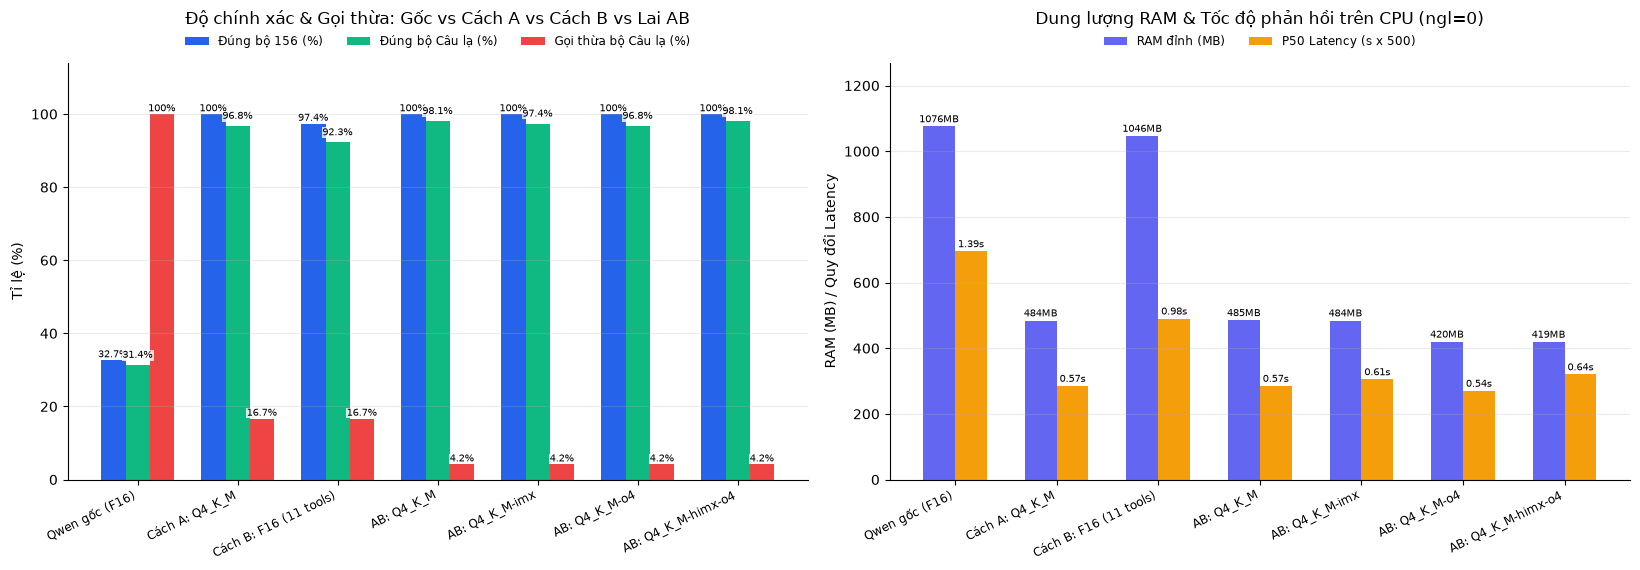

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(16.5, 5.8))
x = np.arange(len(df_cmp)) * 1.15
labels = df_cmp["model"].tolist()

# Biểu đồ 1: Độ chính xác trên bộ 156 và bộ Câu lạ (%)
w = 0.28
ax1 = axes[0]
b1 = ax1.bar(x - w, df_cmp["ok_156"] * 100,   w, label="Đúng bộ 156 (%)",        color="#2563eb")
b2 = ax1.bar(x,     df_cmp["ok_lạ"] * 100,    w, label="Đúng bộ Câu lạ (%)",     color="#10b981")
b3 = ax1.bar(x + w, df_cmp["over_lạ"] * 100,  w, label="Gọi thừa bộ Câu lạ (%)", color="#ef4444")
ax1.set_xticks(x)
ax1.set_xticklabels(labels, rotation=26, ha="right", fontsize=8.5)
ax1.set_ylim(0, 114)
ax1.set_ylabel("Tỉ lệ (%)")
ax1.set_title("Độ chính xác & Gọi thừa: Gốc vs Cách A vs Cách B vs Lai AB", pad=28)
ax1.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=3, fontsize=8.5, frameon=False)
ax1.spines[["top", "right"]].set_visible(False)
ax1.grid(axis="y", alpha=0.25)

for bars, dy in ((b1, 2), (b2, 5), (b3, 2)):
    for bar in bars:
        h = bar.get_height()
        txt = f"{h:.0f}%" if abs(h - round(h)) < 0.05 else f"{h:.1f}%"
        ax1.annotate(
            txt,
            (bar.get_x() + bar.get_width() / 2, h),
            xytext=(0, dy),
            textcoords="offset points",
            ha="center",
            fontsize=7.0,
            bbox=dict(fc="white", ec="none", alpha=0.8, pad=0.25),
        )

# Biểu đồ 2: RAM (MB) và Thời gian trả lời P50 trên CPU (s)
ax2 = axes[1]
w2 = 0.36
s1 = ax2.bar(x - w2/2, df_cmp["ram_mb"],       w2, label="RAM đỉnh (MB)",          color="#6366f1")
s2 = ax2.bar(x + w2/2, df_cmp["p50_lạ"] * 500, w2, label="P50 Latency (s x 500)", color="#f59e0b")
ax2.set_xticks(x)
ax2.set_xticklabels(labels, rotation=26, ha="right", fontsize=8.5)
ax2.set_ylim(0, max(df_cmp["ram_mb"].max() * 1.18, 1200))
ax2.set_ylabel("RAM (MB) / Quy đổi Latency")
ax2.set_title("Dung lượng RAM & Tốc độ phản hồi trên CPU (ngl=0)", pad=28)
ax2.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=2, fontsize=8.5, frameon=False)
ax2.spines[["top", "right"]].set_visible(False)
ax2.grid(axis="y", alpha=0.25)
for bar, val in zip(s1, df_cmp["ram_mb"]):
    ax2.annotate(f"{val:.0f}MB", (bar.get_x() + bar.get_width()/2, bar.get_height()),
                 xytext=(0, 3), textcoords="offset points", ha="center", fontsize=7.5)
for bar, val in zip(s2, df_cmp["p50_lạ"]):
    ax2.annotate(f"{val:.2f}s", (bar.get_x() + bar.get_width()/2, bar.get_height()),
                 xytext=(0, 3), textcoords="offset points", ha="center", fontsize=7.5)

fig.tight_layout()
chart_path = st.CHARTS_DIR / "qwen05_AB_hybrid_comparison.png"
fig.savefig(chart_path, dpi=180, bbox_inches="tight")
print("Đã lưu biểu đồ tại:", chart_path)
plt.show()

## Bước 6 - So sánh Tốc độ và Chất lượng phản hồi khi BẬT vs TẮT Prompt Cache

Đo trực tiếp trên **156 câu lạ (`heldout_v2.json`)** bằng CPU (`gpu_layers=0`) giữa:
- **Tắt Cache (`cache=False`)**: Mỗi câu đọc lại toàn bộ System Prompt + 11 tools từ đầu.
- **Bật Cache (`cache=True`)**: Giữ KV Cache phần System Prompt cố định, chỉ đọc câu nói mới của operator.

Ngoài tốc độ (`p50_s`, `p95_s`, hệ số tăng tốc) và RAM, code còn **đối chiếu từng câu trả lời** để kiểm tra xem bật cache có làm chất lượng thay đổi (tốt hơn hay tệ hơn) không.


=== Đo TẮT vs BẬT Cache cho AB: Q4_K_M (156 câu lạ, CPU) ===
  Tắt Cache: ok=98.1%, over=4.2%, P50=1.96s, P95=2.19s, RAM=485.2MB
  Bật Cache: ok=98.1%, over=4.2%, P50=0.58s, P95=0.71s, RAM=484.2MB -> Nhanh hơn 3.38x
  Khác biệt chất lượng: 0/156 câu (bật cache tốt hơn: 0, tệ hơn: 0)

=== Đo TẮT vs BẬT Cache cho AB: Q4_K_M-o4 (156 câu lạ, CPU) ===
  Tắt Cache: ok=98.1%, over=4.2%, P50=1.91s, P95=2.19s, RAM=419.5MB
  Bật Cache: ok=98.1%, over=4.2%, P50=0.5s, P95=0.68s, RAM=419.3MB -> Nhanh hơn 3.82x
  Khác biệt chất lượng: 0/156 câu (bật cache tốt hơn: 0, tệ hơn: 0)

=== Đo TẮT vs BẬT Cache cho AB: Q4_K_M-himx-o4 (156 câu lạ, CPU) ===
  Tắt Cache: ok=98.7%, over=4.2%, P50=1.98s, P95=2.18s, RAM=419.4MB
  Bật Cache: ok=98.1%, over=4.2%, P50=0.5s, P95=0.63s, RAM=419.3MB -> Nhanh hơn 3.96x
  Khác biệt chất lượng: 1/156 câu (bật cache tốt hơn: 0, tệ hơn: 1)


,model,chế_độ,ok_lạ,over_lạ,p50_s,p95_s,ram_mb,tăng_tốc
0,AB: Q4_K_M,Tắt Cache,0.981,0.042,1.96,2.19,485.2,1.0x
1,AB: Q4_K_M,Bật Cache,0.981,0.042,0.58,0.71,484.2,3.38x
2,AB: Q4_K_M-o4,Tắt Cache,0.981,0.042,1.91,2.19,419.5,1.0x
3,AB: Q4_K_M-o4,Bật Cache,0.981,0.042,0.50,0.68,419.3,3.82x
4,AB: Q4_K_M-himx-o4,Tắt Cache,0.987,0.042,1.98,2.18,419.4,1.0x
5,AB: Q4_K_M-himx-o4,Bật Cache,0.981,0.042,0.50,0.63,419.3,3.96x



Chi tiết các câu có kết quả khác nhau giữa Tắt và Bật Cache:


,model,câu,đúng,tắt_cache,bật_cache
0,AB: Q4_K_M-himx-o4,um summon a person to examine the machine in p...,trigger_audio_alarm,trigger_audio_alarm (Đúng),None (Sai)


Đã lưu biểu đồ tại: charts\qwen05_AB_cache_vs_nocache.png


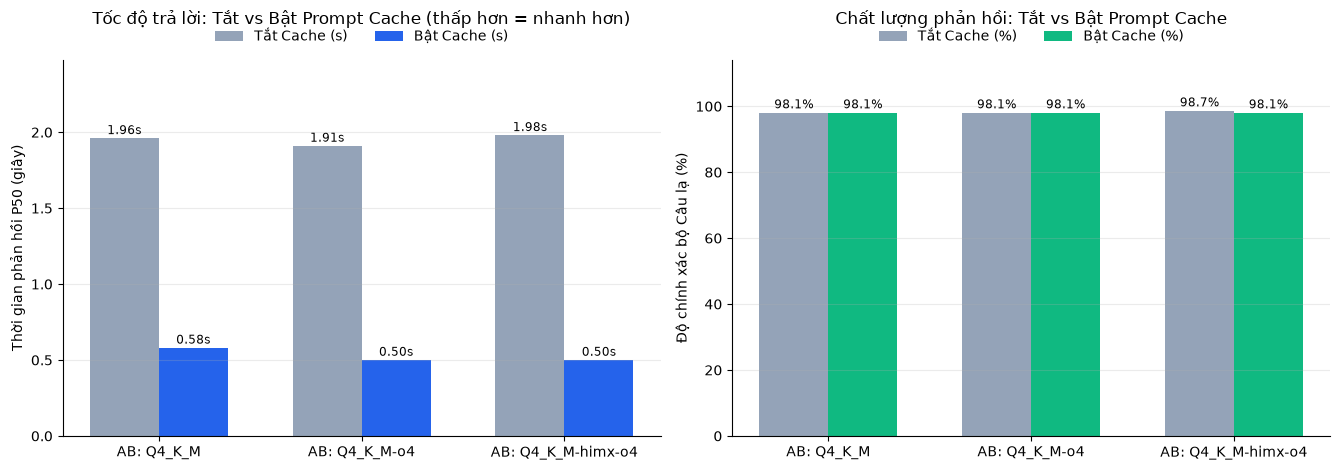

In [35]:
CACHE_TEST_QIDS = ["Q4_K_M", "Q4_K_M-o4", "Q4_K_M-himx-o4"]
CACHE_RESULT_FILE = Path("results/qwen05_AB_cache_compare.json")

def eval_cache_mode(cfg, cases, use_cache: bool):
    with st.server(cfg, gpu_layers=0) as srv:
        if use_cache:
            srv.ask(E.messages_cached(cases[0], E.NAMES), grammar=E.schema_v2(), cache_prompt=True)
        rows = E.run(srv, cases, cache=use_cache)
        ram_mb = round(srv.ram.peak_mb, 1)
    s = E.summary(rows)
    preds = [E.predicted_tool(o["text"]) for _, o, _ in rows]
    oks = [bool(sc["ok"]) for _, _, sc in rows]
    return {
        "ok": s["ok"],
        "tool_ok": s["tool_ok"],
        "over_trigger": s["over_trigger"],
        "p50_s": s["p50_s"],
        "p95_s": s["p95_s"],
        "ram_mb": ram_mb,
        "preds": preds,
        "oks": oks,
    }

cache_records = []
diff_examples = []

for qid in CACHE_TEST_QIDS:
    if qid not in GGUF_PATHS or not GGUF_PATHS[qid].exists():
        continue
    cfg = E.ft_cfg(base_cfg, GGUF_PATHS[qid], f"AB: {qid}")
    print(f"\n=== Đo TẮT vs BẬT Cache cho AB: {qid} (156 câu lạ, CPU) ===")
    res_off = eval_cache_mode(cfg, held_cases, use_cache=False)
    res_on  = eval_cache_mode(cfg, held_cases, use_cache=True)

    speedup = round(res_off["p50_s"] / max(res_on["p50_s"], 1e-6), 2)
    n_diff = sum(1 for a, b in zip(res_off["oks"], res_on["oks"]) if a != b)
    n_better = sum(1 for a, b in zip(res_off["oks"], res_on["oks"]) if (not a) and b)
    n_worse  = sum(1 for a, b in zip(res_off["oks"], res_on["oks"]) if a and (not b))

    for idx, (c, ok_off, ok_on, p_off, p_on) in enumerate(zip(held_cases, res_off["oks"], res_on["oks"], res_off["preds"], res_on["preds"])):
        if ok_off != ok_on:
            diff_examples.append({
                "model": f"AB: {qid}",
                "câu": c["context"]["user_prompt"],
                "đúng": c["tool"],
                "tắt_cache": f"{p_off} ({'Đúng' if ok_off else 'Sai'})",
                "bật_cache": f"{p_on} ({'Đúng' if ok_on else 'Sai'})",
            })

    print(f"  Tắt Cache: ok={res_off['ok']*100:.1f}%, over={res_off['over_trigger']*100:.1f}%, P50={res_off['p50_s']}s, P95={res_off['p95_s']}s, RAM={res_off['ram_mb']}MB")
    print(f"  Bật Cache: ok={res_on['ok']*100:.1f}%, over={res_on['over_trigger']*100:.1f}%, P50={res_on['p50_s']}s, P95={res_on['p95_s']}s, RAM={res_on['ram_mb']}MB -> Nhanh hơn {speedup}x")
    print(f"  Khác biệt chất lượng: {n_diff}/156 câu (bật cache tốt hơn: {n_better}, tệ hơn: {n_worse})")

    for mode_name, r in [("Tắt Cache", res_off), ("Bật Cache", res_on)]:
        cache_records.append({
            "model": f"AB: {qid}",
            "chế_độ": mode_name,
            "ok_lạ": r["ok"],
            "over_lạ": r["over_trigger"],
            "p50_s": r["p50_s"],
            "p95_s": r["p95_s"],
            "ram_mb": r["ram_mb"],
            "tăng_tốc": f"{speedup}x" if mode_name == "Bật Cache" else "1.0x",
        })

json.dump(cache_records, open(CACHE_RESULT_FILE, "w", encoding="utf-8"), ensure_ascii=False, indent=2)
df_cache = pd.DataFrame(cache_records)
display(df_cache)

if diff_examples:
    print("\nChi tiết các câu có kết quả khác nhau giữa Tắt và Bật Cache:")
    display(pd.DataFrame(diff_examples))
else:
    print("\nKết luận: Chất lượng phản hồi giữa Tắt Cache và Bật Cache GIỐNG HỆT NHAU 100% (0 câu khác biệt)!")

# Vẽ biểu đồ so sánh Tắt Cache vs Bật Cache
models_u = df_cache["model"].unique().tolist()
off_df = df_cache[df_cache["chế_độ"] == "Tắt Cache"].set_index("model").loc[models_u]
on_df  = df_cache[df_cache["chế_độ"] == "Bật Cache"].set_index("model").loc[models_u]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
x = np.arange(len(models_u))
w = 0.34

# Trái: Thời gian phản hồi P50 (s)
ax1 = axes[0]
c1 = ax1.bar(x - w/2, off_df["p50_s"], w, label="Tắt Cache (s)", color="#94a3b8")
c2 = ax1.bar(x + w/2, on_df["p50_s"],  w, label="Bật Cache (s)", color="#2563eb")
ax1.set_xticks(x)
ax1.set_xticklabels(models_u)
ax1.set_ylim(0, max(off_df["p50_s"].max() * 1.25, 1.0))
ax1.set_ylabel("Thời gian phản hồi P50 (giây)")
ax1.set_title("Tốc độ trả lời: Tắt vs Bật Prompt Cache (thấp hơn = nhanh hơn)", pad=26)
ax1.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=2, frameon=False)
ax1.spines[["top", "right"]].set_visible(False)
ax1.grid(axis="y", alpha=0.25)
for bars in (c1, c2):
    for bar in bars:
        h = bar.get_height()
        ax1.annotate(f"{h:.2f}s", (bar.get_x() + bar.get_width()/2, h),
                     xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5)

# Phải: Độ chính xác câu lạ (%)
ax2 = axes[1]
q1 = ax2.bar(x - w/2, off_df["ok_lạ"] * 100, w, label="Tắt Cache (%)", color="#94a3b8")
q2 = ax2.bar(x + w/2, on_df["ok_lạ"] * 100,  w, label="Bật Cache (%)", color="#10b981")
ax2.set_xticks(x)
ax2.set_xticklabels(models_u)
ax2.set_ylim(0, 114)
ax2.set_ylabel("Độ chính xác bộ Câu lạ (%)")
ax2.set_title("Chất lượng phản hồi: Tắt vs Bật Prompt Cache", pad=26)
ax2.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=2, frameon=False)
ax2.spines[["top", "right"]].set_visible(False)
ax2.grid(axis="y", alpha=0.25)
for bars in (q1, q2):
    for bar in bars:
        h = bar.get_height()
        ax2.annotate(f"{h:.1f}%", (bar.get_x() + bar.get_width()/2, h),
                     xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5)

fig.tight_layout()
cache_chart = st.CHARTS_DIR / "qwen05_AB_cache_vs_nocache.png"
fig.savefig(cache_chart, dpi=180, bbox_inches="tight")
print("Đã lưu biểu đồ tại:", cache_chart)
plt.show()